<a href="https://colab.research.google.com/github/brittanybee-alt/Capstone-Project-Three/blob/main/Capstone_Three_Preprocessing_%5BBrittany_Barrion%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Three, Step 4: Pre-processing and Training Data Development
## Investigating Fatigue-Related Aviation Safety Reports Through Statistical Analysis and Natural Language Processing

**Author:** Brittany | Springboard Data Science Career Track, Capstone Three

**Research question:** What statistical patterns and recurring narrative themes characterize fatigue-related aviation safety reports submitted to NASA's Aviation Safety Reporting System (ASRS) between 2009 and 2025?

**Input:** `asrs_fatigue_eda_features.csv` (2,191 reports, 58 columns), created at the end of `02_EDA.ipynb`

**Goal of this step:** turn the EDA dataset into model-ready training and testing data. Springboard's three required steps are **dummy features**, **scaling**, and a **train/test split**, and each one is applied where it makes sense for this project.

| Section | What happens |
|---|---|
| 1 | Load the EDA dataset |
| 2 | What "modeling" means in this project, and which data goes into which model |
| 3 | Guiding question 1: categorical data → dummy (one-hot) features |
| 4 | Guiding question 2: feature ranges → standardization |
| 5 | Train/test split |
| 6 | Text pre-processing: TF-IDF and count matrices (the text version of scaling) |
| 7 | Save the development datasets |

### 0. Setup

In [1]:
import os
import re
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

PROCESSED_DIR = "data/processed"
MODEL_DIR = "models"
FIG_DIR = "figures"
for folder in [PROCESSED_DIR, MODEL_DIR, FIG_DIR]:
    os.makedirs(folder, exist_ok=True)

def find_or_upload(filename):
    """Look for the file in data/processed/, then in /content/; otherwise ask for an upload (Colab)."""
    for path in [os.path.join(PROCESSED_DIR, filename), os.path.join("/content", filename)]:
        if os.path.exists(path):
            return path
    try:
        from google.colab import files
        uploaded = files.upload()
        target = os.path.join(PROCESSED_DIR, filename)
        shutil.move(next(iter(uploaded)), target)
        return target
    except ImportError:
        raise FileNotFoundError(f"Run the EDA notebook first, or place {filename} in {PROCESSED_DIR}/")

## 1. Load the EDA Dataset

In [2]:
EDA_FILE = find_or_upload("/content/asrs_fatigue_eda_features.csv")
df = pd.read_csv(EDA_FILE, parse_dates=["date"], low_memory=False)
df["text_lemma"] = df["text_lemma"].fillna("")
print("Loaded:", EDA_FILE)
print("Shape:", df.shape)
assert len(df) == 2191 and df["acn"].is_unique, "Expected 2,191 unique reports. Re-run the wrangling and EDA notebooks."

Loaded: /content/asrs_fatigue_eda_features.csv
Shape: (2191, 58)


## 2. What Does "Modeling" Mean in This Project?

Springboard's modeling step is written for **supervised** projects, where you predict a response variable. As explained in the EDA notebook, this project has **no response variable**: it explores fatigue-related reports and doesn't predict an outcome. So the modeling step has two parts, and each needs its own model-ready data:

| Part | Model type | Input data | Prepared in this notebook as |
|---|---|---|---|
| **A. Find the themes** (main model) | **Unsupervised topic models**: NMF, LDA, K-Means | Cleaned narratives (`text_lemma`) | TF-IDF matrix (for NMF and K-Means) and word-count matrix (for LDA) |
| **B. Connect themes to report characteristics** (integration) | **Supervised** multinomial logistic regression: can a report's flight phase, time of day, reporter role, mission, operator, year and human factors predict its main theme? | Structured features | Dummy features + standardized numeric features + 0/1 human-factor indicators |

Part B is where dummy features and scaling matter most, because logistic regression needs numbers on comparable scales. Part A needs its own kind of "scaling" for text (TF-IDF). **Both parts use the same train/test split**, so every model is judged on reports it never saw during training.

## 3. Guiding Question 1: Does the Dataset Have Categorical Data?

**Yes.** The EDA selected five categorical features as comparison lenses: flight phase group, time of day, reporter role, mission and operator. A model can't use text labels like `"Cruise"` or `"Pilot"` directly, so each category becomes its own **0/1 dummy column** (one-hot encoding).

In [3]:
CATEGORICAL = ["phase_group", "time_of_day", "reporter_role", "mission", "operator"]
for col in CATEGORICAL:
    print(f"{col}: {df[col].value_counts().to_dict()}")

phase_group: {'Descent & Approach': 698, 'Ground': 563, 'Takeoff & Climb': 312, 'Cruise': 244, 'Unknown': 197, 'Landing': 133, 'Other': 44}
time_of_day: {'1801-2400': 543, '0601-1200': 506, '1201-1800': 506, '0001-0600': 406, 'Unknown': 230}
reporter_role: {'Pilot': 1768, 'Air Traffic Control': 132, 'Maintenance': 129, 'Flight Attendant': 96, 'Other': 21, 'Dispatcher': 18, 'UAS Operator': 15, 'Unknown': 12}
mission: {'Passenger': 1327, 'Unknown': 424, 'Cargo': 163, 'Personal': 95, 'Ferry / Repositioning': 86, 'Training': 52, 'Other': 44}
operator: {'Air Carrier': 1591, 'Unknown': 172, 'Personal': 129, 'Air Taxi': 101, 'Corporate': 67, 'Fractional': 66, 'Other': 33, 'FBO': 32}


### 3.1 Combine categories that are too small to model
The EDA used a rule of thumb that groups with **fewer than 50 reports** are too small for reliable comparisons. A dummy column with only 12–40 reports gives the model almost nothing to learn from and makes its coefficient unstable. So before creating dummies I apply one consistent rule to all five features: **any category with fewer than 50 reports, plus the existing "Other" and "Unknown" catch-all categories, is combined into a single "Other / Unknown" category.** This affects, for example, Dispatcher (18) and UAS Operator (15) in reporter role, and FBO (32) in operator. The original columns stay in the data unchanged. The combined versions get a `_model` suffix.

In [4]:
MIN_GROUP = 50

def combine_small(series, min_n=MIN_GROUP):
    counts = series.value_counts()
    small = counts[counts < min_n].index
    return series.where(~(series.isin(small) | series.isin(["Other", "Unknown"])), "Other / Unknown")

CATEGORICAL_MODEL = []
for col in CATEGORICAL:
    df[f"{col}_model"] = combine_small(df[col])
    CATEGORICAL_MODEL.append(f"{col}_model")
    print(f"{col}_model: {df[f'{col}_model'].value_counts().to_dict()}")

phase_group_model: {'Descent & Approach': 698, 'Ground': 563, 'Takeoff & Climb': 312, 'Cruise': 244, 'Other / Unknown': 241, 'Landing': 133}
time_of_day_model: {'1801-2400': 543, '0601-1200': 506, '1201-1800': 506, '0001-0600': 406, 'Other / Unknown': 230}
reporter_role_model: {'Pilot': 1768, 'Air Traffic Control': 132, 'Maintenance': 129, 'Flight Attendant': 96, 'Other / Unknown': 66}
mission_model: {'Passenger': 1327, 'Other / Unknown': 468, 'Cargo': 163, 'Personal': 95, 'Ferry / Repositioning': 86, 'Training': 52}
operator_model: {'Air Carrier': 1591, 'Other / Unknown': 237, 'Personal': 129, 'Air Taxi': 101, 'Corporate': 67, 'Fractional': 66}


### 3.2 Create the dummy features

**Should one category be dropped (`drop_first=True`)?** In an *ordinary* linear or logistic regression, keeping every category creates perfect multicollinearity (the "dummy variable trap"): the dummies for one feature always add up to 1, so one of them is redundant. Dropping one category, the *reference level*, fixes that.

**Decision: keep all categories (`drop_first=False`).** The integration model in Step 5 is a **regularized** logistic regression. Regularization (the L2 penalty) shrinks coefficients and handles the redundant column without trouble, and keeping every category means each one gets its own readable coefficient. For example, "Ground" and "Cruise" can be compared directly, without everything being relative to a hidden baseline. I'd switch to `drop_first=True` if I used an unregularized model.

In [5]:
dummies = pd.get_dummies(df[CATEGORICAL_MODEL], prefix=["phase", "tod", "role", "mission", "operator"], dtype=int)
dummies.columns = [re.sub(r"[^a-z0-9]+", "_", c.lower().replace("&", "and")).strip("_") for c in dummies.columns]
print("Dummy columns created:", dummies.shape[1])
display(dummies.head())

check = pd.concat([df[CATEGORICAL_MODEL], dummies], axis=1).iloc[:3]
display(check)
print("Every report has exactly one dummy per feature:",
      all((dummies.filter(like=p).sum(axis=1) == 1).all() for p in ["phase_", "tod_", "role_", "mission_", "operator_"]))

Dummy columns created: 28


,phase_cruise,phase_descent_and_approach,phase_ground,phase_landing,phase_other_unknown,phase_takeoff_and_climb,tod_0001_0600,tod_0601_1200,tod_1201_1800,tod_1801_2400,tod_other_unknown,role_air_traffic_control,role_flight_attendant,role_maintenance,role_other_unknown,role_pilot,mission_cargo,mission_ferry_repositioning,mission_other_unknown,mission_passenger,mission_personal,mission_training,operator_air_carrier,operator_air_taxi,operator_corporate,operator_fractional,operator_other_unknown,operator_personal
0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
2,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0
3,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
4,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0


,phase_group_model,time_of_day_model,reporter_role_model,mission_model,operator_model,phase_cruise,phase_descent_and_approach,phase_ground,phase_landing,phase_other_unknown,phase_takeoff_and_climb,tod_0001_0600,tod_0601_1200,tod_1201_1800,tod_1801_2400,tod_other_unknown,role_air_traffic_control,role_flight_attendant,role_maintenance,role_other_unknown,role_pilot,mission_cargo,mission_ferry_repositioning,mission_other_unknown,mission_passenger,mission_personal,mission_training,operator_air_carrier,operator_air_taxi,operator_corporate,operator_fractional,operator_other_unknown,operator_personal
0,Ground,0601-1200,Pilot,Passenger,Air Carrier,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0
1,Landing,0601-1200,Pilot,Personal,Personal,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1
2,Ground,0601-1200,Pilot,Cargo,Air Carrier,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0


Every report has exactly one dummy per feature: True


## 4. Guiding Question 2: Do Feature Values Range 0–100, 0–1, or Both?

**Both, and more.** The structured features going into the integration model sit on very different scales:

In [6]:
HF_COLS = [c for c in df.columns if c.startswith("hf_")]
NUMERIC = ["year", "log_narrative_words"]

ranges = pd.DataFrame({
    "feature (or group)": ["dummy features (35 columns)", "human-factor indicators (11 columns)", "year", "log_narrative_words"],
    "min": [dummies.values.min(), df[HF_COLS].values.min(), df["year"].min(), round(df["log_narrative_words"].min(), 2)],
    "max": [dummies.values.max(), df[HF_COLS].values.max(), df["year"].max(), round(df["log_narrative_words"].max(), 2)],
    "type": ["binary 0/1", "binary 0/1", "integer, ~2,000s", "continuous"],
})
ranges.loc[0, "feature (or group)"] = f"dummy features ({dummies.shape[1]} columns)"
ranges.loc[1, "feature (or group)"] = f"human-factor indicators ({len(HF_COLS)} columns)"
display(ranges)

,feature (or group),min,max,type
0,dummy features (28 columns),0.00,1.00,binary 0/1
1,human-factor indicators (11 columns),0.00,1.00,binary 0/1
2,year,2009.00,2025.00,"integer, ~2,000s"
3,log_narrative_words,1.18,3.35,continuous


**Why this matters.** `year` runs from 2009 to 2025, while every binary feature is 0 or 1. In a regularized model, the penalty treats all coefficients the same. A feature measured in big units would get a tiny coefficient and slip past the penalty, and a 0/1 feature would be penalized more heavily, just because of its units. **Standardization** (subtract the mean, divide by the standard deviation) puts the continuous features on a common scale with mean 0 and SD 1, so the model compares features by what they *mean*, not by their units.

**Which features get scaled:**

| Feature | Scale it? | Reason |
|---|---|---|
| `year` | **Yes** | Large values (2009–2025) |
| `log_narrative_words` | **Yes** | Continuous. Already log-transformed in EDA to fix skew; standardizing centers it |
| Dummy and human-factor 0/1 columns | **No** | Already on a 0/1 scale. Standardizing them would turn "present or absent" into hard-to-read decimals without helping the model |
| Flight hours (total, 90-day) | **Not used** | ~67–69% missing (pilots only). EDA decided to *describe only* |
| Counts of factors (`n_human_factors`, etc.) | **Not used** | Built from the indicator columns, so they would repeat information the model already has (EDA Section 8) |

**Important:** the scaler is **fit on the training data only** and then applied to the test data (Section 5.2). Fitting it on all the data would let information about the test reports (their mean and spread) leak into training. This is called *data leakage*.

## 5. Train/Test Split

**Does the data involve a time series or forecasting?** No. I'm not predicting future reports, so a **random split** is appropriate. A time-based split (train on early years, test on later ones) would only be needed for forecasting. Because the EDA found that report volume declines over time, I check below that the train and test sets have similar year distributions.

**Decisions:**
- **80% training / 20% testing.** With 2,191 reports, that's about 1,750 for training and about 440 for testing. That's enough test reports to judge whether topics hold up on unseen narratives.
- **Stratified by `phase_group`.** Flight phase is the main comparison lens, so stratifying keeps the same phase mix in both sets.
- **`random_state=42`** makes the split reproducible.

In [7]:
train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=42, stratify=df["phase_group"]
)
print(f"Training reports: {len(train_idx)} | Testing reports: {len(test_idx)}")

compare = pd.DataFrame({
    "train %": df.loc[train_idx, "phase_group"].value_counts(normalize=True).mul(100).round(1),
    "test %": df.loc[test_idx, "phase_group"].value_counts(normalize=True).mul(100).round(1),
})
display(compare)

Training reports: 1752 | Testing reports: 439


,train %,test %
phase_group,,
Descent & Approach,31.8,31.9
Ground,25.7,25.7
Takeoff & Climb,14.3,14.1
Cruise,11.1,11.2
Unknown,9.0,8.9
Landing,6.1,6.2
Other,2.0,2.1


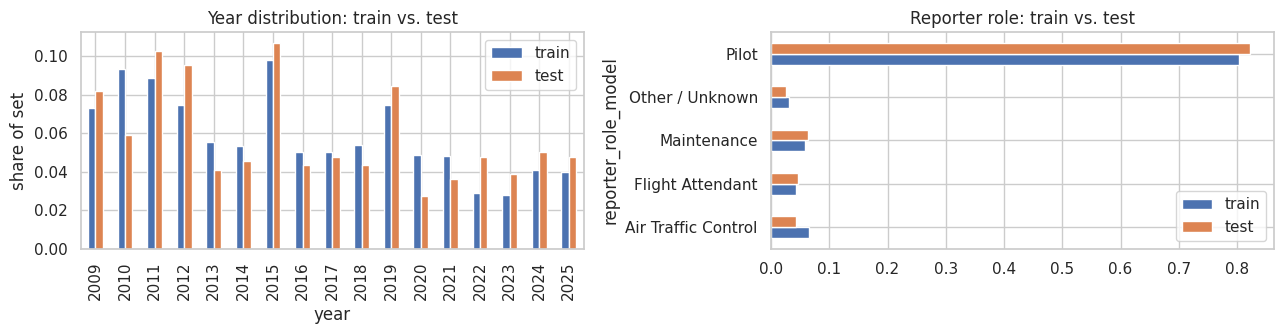

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
pd.DataFrame({"train": df.loc[train_idx, "year"].value_counts(normalize=True),
              "test": df.loc[test_idx, "year"].value_counts(normalize=True)}).sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Year distribution: train vs. test")
axes[0].set_ylabel("share of set")
pd.DataFrame({"train": df.loc[train_idx, "reporter_role_model"].value_counts(normalize=True),
              "test": df.loc[test_idx, "reporter_role_model"].value_counts(normalize=True)}).plot.barh(ax=axes[1])
axes[1].set_title("Reporter role: train vs. test")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "pre_01_train_test_balance.png"), dpi=150)
plt.show()

**Check result.** The phase mix is nearly identical in both sets (that's what stratifying guarantees), and the year and reporter-role distributions also line up closely. So the test set is a fair sample of the full dataset.

### 5.1 Build the structured feature matrix

In [9]:
X_struct = pd.concat([dummies, df[HF_COLS], df[NUMERIC]], axis=1)
X_struct.index = df.index
print("Structured feature matrix:", X_struct.shape)
print("Missing values:", X_struct.isna().sum().sum())

Structured feature matrix: (2191, 41)
Missing values: 0


### 5.2 Standardize the numeric features (fit on training data only)

,train mean (after),train SD (after),test mean (after),test SD (after),scaler mean (learned),scaler SD (learned)
year,0.0,1.0,0.049,1.038,2015.69,4.72
log_narrative_words,-0.0,1.0,-0.038,0.998,2.50,0.30


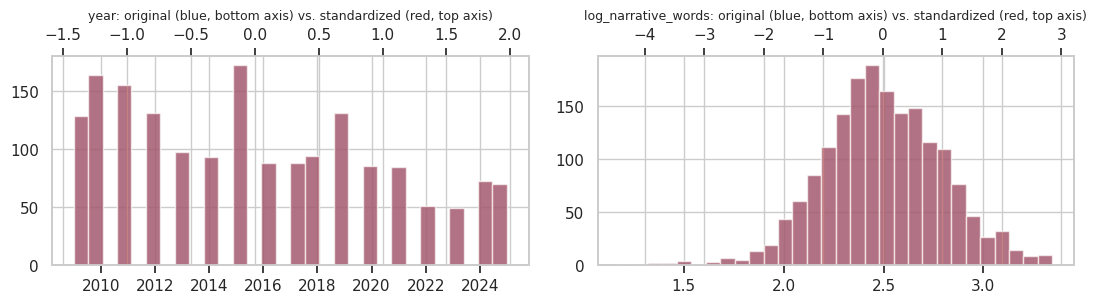

In [10]:
scaler = StandardScaler()
X_struct_train = X_struct.loc[train_idx].copy()
X_struct_test = X_struct.loc[test_idx].copy()

X_struct_train[NUMERIC] = scaler.fit_transform(X_struct_train[NUMERIC])   # learn mean/SD from TRAIN
X_struct_test[NUMERIC] = scaler.transform(X_struct_test[NUMERIC])         # apply the SAME numbers to TEST

summary = pd.DataFrame({
    "train mean (after)": X_struct_train[NUMERIC].mean().round(3),
    "train SD (after)": X_struct_train[NUMERIC].std().round(3),
    "test mean (after)": X_struct_test[NUMERIC].mean().round(3),
    "test SD (after)": X_struct_test[NUMERIC].std().round(3),
    "scaler mean (learned)": pd.Series(scaler.mean_, index=NUMERIC).round(2),
    "scaler SD (learned)": pd.Series(scaler.scale_, index=NUMERIC).round(2),
})
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, col in zip(axes, NUMERIC):
    ax.hist(X_struct.loc[train_idx, col], bins=30, alpha=0.6, label="before")
    ax2 = ax.twiny()
    ax2.hist(X_struct_train[col], bins=30, alpha=0.6, color="#C44E52", label="after")
    ax.set_title(f"{col}: original (blue, bottom axis) vs. standardized (red, top axis)", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "pre_02_scaling.png"), dpi=150)
plt.show()

**What the scaling did.** After scaling, both numeric features have a training mean of exactly 0 and SD of 1. The test set's mean and SD are *close to* 0 and 1 but not exact. That's expected and correct, because the test data was transformed with the **training** mean and SD, as it would be for brand-new reports. The shape of each distribution is unchanged: scaling only moves and stretches the axis.

## 6. Text Pre-processing: TF-IDF and Word Counts

The narratives are the main model input. Turning text into numbers is the text version of "standardizing magnitude." Each narrative becomes a row of numbers, one column per word or two-word phrase.

**Two matrices are built, because the topic models need different inputs:**

| Matrix | Used by | Why |
|---|---|---|
| **TF-IDF** | NMF, K-Means | Weights each word by how often it appears in a report (TF), down-weighted by how many reports use it (IDF), so distinctive words count more than common ones. Each row is then normalized to length 1, so a 2,000-word narrative and a 200-word narrative are on the same scale. That's the "scaling" step for text, and it addresses EDA finding 7.4 that narrative length differs by reporter role. |
| **Word counts** | LDA | LDA is a probability model of how words are generated, so it expects raw word counts rather than weights. |

**Settings, all carried over from the EDA (Section 9.5):**
- `ngram_range=(1, 2)`: single words and two-word phrases. EDA showed phrases like *duty day*, *crew scheduling* and *first officer* carry meaning.
- `min_df=5`: drop words used in fewer than 5 narratives (typos and one-off details).
- `max_df=0.5`: drop words used in more than half of narratives (*time, flight, aircraft, day, would*), which can't separate themes.
- `sublinear_tf=True` (TF-IDF only): uses 1 + log(count), so a word repeated 20 times in one long report doesn't overwhelm the rest of it.
- **Custom stop words:** filler words that NLTK's list misses and that EDA found among the most common words. They include `u`, which is how the lemmatizer shortens *us*.

Both vectorizers are **fit on the training narratives only**, then applied to the test narratives, which prevents data leakage just like the scaler.

In [11]:
CUSTOM_STOP_WORDS = ["u", "us", "back", "could", "also", "get", "got", "one", "due", "told", "asked", "said",
                     "gave", "would", "went", "going", "way", "even", "still", "made", "make", "sure",
                     "know", "think", "felt"]

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5, stop_words=CUSTOM_STOP_WORDS, sublinear_tf=True)
X_tfidf_train = tfidf.fit_transform(df.loc[train_idx, "text_lemma"])
X_tfidf_test = tfidf.transform(df.loc[test_idx, "text_lemma"])

counter = CountVectorizer(ngram_range=(1, 2), vocabulary=tfidf.vocabulary_)   # same vocabulary as TF-IDF
X_count_train = counter.transform(df.loc[train_idx, "text_lemma"])
X_count_test = counter.transform(df.loc[test_idx, "text_lemma"])

vocab = tfidf.get_feature_names_out()
print("TF-IDF train:", X_tfidf_train.shape, "| test:", X_tfidf_test.shape)
print("Count  train:", X_count_train.shape, "| test:", X_count_test.shape)
print("Vocabulary size:", len(vocab), f"(of which two-word phrases: {sum(' ' in t for t in vocab)})")
print(f"Matrix sparsity (share of zeros): {1 - X_tfidf_train.nnz / np.prod(X_tfidf_train.shape):.3f}")

TF-IDF train: (1752, 9925) | test: (439, 9925)
Count  train: (1752, 9925) | test: (439, 9925)
Vocabulary size: 9925 (of which two-word phrases: 5660)
Matrix sparsity (share of zeros): 0.985


**Why the counts use the TF-IDF vocabulary.** Sharing one vocabulary means all three topic models see exactly the same words, so the comparison in Step 5 is fair: differences come from the *algorithms*, not from different word lists.

**About sparsity.** About 98.5% of the matrix is zeros, because each narrative uses only a small slice of the vocabulary. That's normal for text. scikit-learn stores it as a *sparse matrix* that only keeps the non-zero values, which saves a lot of memory.

In [12]:
row_lengths = np.sqrt(X_tfidf_train.multiply(X_tfidf_train).sum(axis=1)).A1
print("Every TF-IDF row has length 1 after normalization:", np.allclose(row_lengths[row_lengths > 0], 1.0))
print("Narratives with no vocabulary words left (empty rows):",
      int((X_tfidf_train.getnnz(axis=1) == 0).sum()), "train |", int((X_tfidf_test.getnnz(axis=1) == 0).sum()), "test")

example = df.loc[train_idx[0]]
row = X_tfidf_train[0].toarray().ravel()
top = np.argsort(-row)[:10]
print(f"\nExample (ACN {example['acn']}), start of narrative: {str(example['narrative_1'])[:200]}...")
display(pd.DataFrame({"term": vocab[top], "TF-IDF weight": row[top].round(3)}))

Every TF-IDF row has length 1 after normalization: True
Narratives with no vocabulary words left (empty rows): 0 train | 0 test

Example (ACN 1986258), start of narrative: I was training on radar combined (Normal operation). Aircraft X was northbound at 8000 ft. on course; still in the prior sectors airspace. They made several requests trying to avoid clouds even though...


,term,TF-IDF weight
0,sector,0.232
1,another aircraft,0.190
2,busy complex,0.173
3,resolving,0.173
4,operation aircraft,0.169
5,nordo,0.169
6,taken care,0.166
7,turn time,0.166
8,frequency congestion,0.166
9,realized aircraft,0.163


**Reading the example.** The highest-weighted terms are the ones that make this narrative *distinctive*, not the most common words overall. That's exactly what the topic models need.

## 7. Save the Development Datasets

In [13]:
pd.Series(train_idx, name="row").to_csv(os.path.join(PROCESSED_DIR, "train_index.csv"), index=False)
pd.Series(test_idx, name="row").to_csv(os.path.join(PROCESSED_DIR, "test_index.csv"), index=False)

X_struct_train.assign(acn=df.loc[train_idx, "acn"].values).to_csv(os.path.join(PROCESSED_DIR, "X_struct_train.csv"), index=False)
X_struct_test.assign(acn=df.loc[test_idx, "acn"].values).to_csv(os.path.join(PROCESSED_DIR, "X_struct_test.csv"), index=False)

sparse.save_npz(os.path.join(PROCESSED_DIR, "X_tfidf_train.npz"), X_tfidf_train)
sparse.save_npz(os.path.join(PROCESSED_DIR, "X_tfidf_test.npz"), X_tfidf_test)
sparse.save_npz(os.path.join(PROCESSED_DIR, "X_count_train.npz"), X_count_train)
sparse.save_npz(os.path.join(PROCESSED_DIR, "X_count_test.npz"), X_count_test)

joblib.dump(tfidf, os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib"))
joblib.dump(counter, os.path.join(MODEL_DIR, "count_vectorizer.joblib"))
joblib.dump(scaler, os.path.join(MODEL_DIR, "numeric_scaler.joblib"))

df_out = pd.concat([df, dummies], axis=1)
df_out["split"] = np.where(df_out.index.isin(train_idx), "train", "test")
df_out.to_csv(os.path.join(PROCESSED_DIR, "asrs_fatigue_preprocessed.csv"), index=False)

saved = sorted(os.listdir(PROCESSED_DIR)) + [f"models/{f}" for f in sorted(os.listdir(MODEL_DIR))]
print("Saved files:")
for f in saved:
    print("  -", f)

Saved files:
  - X_count_test.npz
  - X_count_train.npz
  - X_struct_test.csv
  - X_struct_train.csv
  - X_tfidf_test.npz
  - X_tfidf_train.npz
  - asrs_fatigue_preprocessed.csv
  - test_index.csv
  - train_index.csv
  - models/count_vectorizer.joblib
  - models/numeric_scaler.joblib
  - models/tfidf_vectorizer.joblib


## 8. Summary of Pre-processing

| Springboard step | What I did | Why |
|---|---|---|
| **Dummy features** | One-hot encoded 5 categorical features (phase group, time of day, reporter role, mission, operator) into 0/1 columns. Categories with < 50 reports, plus "Other" and "Unknown", were combined into "Other / Unknown" first. All categories kept (`drop_first=False`). | Models need numbers, not labels. Keeping all categories is safe because the Step 5 integration model is regularized, and it keeps every category's coefficient readable. |
| **Scaling** | Standardized `year` and `log_narrative_words` (mean 0, SD 1) with `StandardScaler`, fit on training data only. 0/1 features left as they are. | Features ranged from 0–1 up to the 2000s, and a regularized model needs comparable scales. Fitting on training data only prevents leakage. |
| **Text scaling** | TF-IDF (unigrams + bigrams, `min_df=5`, `max_df=0.5`, sublinear TF, L2 normalization) and a word-count matrix on the same vocabulary, both fit on training narratives only. | TF-IDF emphasizes distinctive words and puts long and short narratives on the same scale. LDA needs raw counts. |
| **Train/test split** | 80/20 random split stratified by flight phase (`random_state=42`). | Not a forecasting problem, so a random split is appropriate. Stratifying keeps the phase mix the same, and the test set lets Step 5 check that themes hold up on unseen reports. |

**Files for Step 5:** `X_tfidf_train/test.npz`, `X_count_train/test.npz`, `X_struct_train/test.csv`, `train_index.csv`, `test_index.csv`, `asrs_fatigue_preprocessed.csv`, and the fitted vectorizers and scaler in `models/`.